In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score

data = pd.read_csv('CC_Customer_Dataset.csv')
data.head()

,Sl_No,Customer Key,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made
0,1,87073,100000,2,1,1,0
1,2,38414,50000,3,0,10,9
2,3,17341,50000,7,1,3,4
3,4,40496,30000,5,1,1,4
4,5,47437,100000,6,0,12,3


## Clustering and Evaluation

In [8]:
features = data.select_dtypes(include=np.number).drop(
    columns=['Customer_ID'], errors='ignore'
)

X = StandardScaler().fit_transform(features)

agg = AgglomerativeClustering(n_clusters=3)
labels = agg.fit_predict(X)

data['Cluster'] = labels

print('Silhouette Score:', silhouette_score(X, labels))
print('Davies-Bouldin Index:', davies_bouldin_score(X, labels))

Silhouette Score: 0.44394092525170764
Davies-Bouldin Index: 0.8516544123096588


## Scatterplot

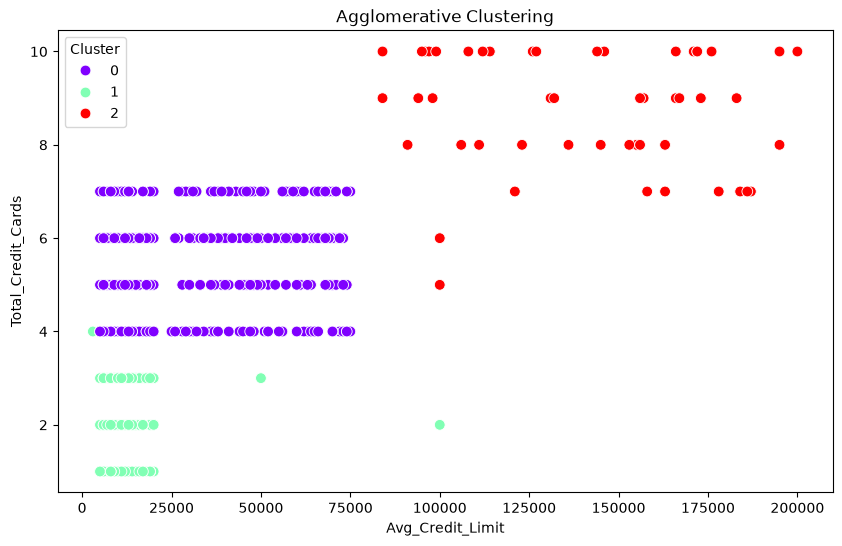

In [9]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=data,
    x='Avg_Credit_Limit',
    y='Total_Credit_Cards',
    hue='Cluster',
    palette='rainbow',
    s=60
)

plt.title('Agglomerative Clustering')
plt.show()